# 04 - AI Business Intelligence: Model Training

This notebook walks through two tasks using the project's existing training functions: sales forecasting with Store Sales data and daily anomaly detection with `train.csv` and `transactions.csv`. The forecast target, `sales`, represents dataset sales units, not monetary revenue. Run the code cells sequentially; no cell has been executed yet.

Both models use the project code in `app/ml/`, keeping training consistent with the API. Trained artifacts are saved through the same storage layer as the API: local files for development, or S3-compatible storage when configured for deployment. Notebook runs use their own generated dataset IDs; to train a model for an app-uploaded dataset, use the Forecasting or Anomalies page.

## Step 1: Imports, dataset path, and project modules

In [8]:
from pathlib import Path
import sys
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_data_dir():
    roots = [Path.cwd(), *Path.cwd().parents]
    candidates = []
    for root in roots:
        candidates.extend(
            [
                root / 'dataset',
                root / 'notebooks' / 'dataset',
                root / 'ai-service' / 'notebooks' / 'dataset',
            ]
        )
    for candidate in candidates:
        if (candidate / 'train.csv').is_file() and (candidate / 'transactions.csv').is_file():
            return candidate
    raise FileNotFoundError('Expected train.csv and transactions.csv in the project dataset folder.')


DATA_DIR = find_data_dir()
AI_SERVICE_DIR = DATA_DIR.parent.parent
if str(AI_SERVICE_DIR) not in sys.path:
    sys.path.insert(0, str(AI_SERVICE_DIR))

from app.ml.anomaly_detection import detect_with_artifact, train_anomaly_model
from app.ml.forecasting import predict_with_artifact
from app.ml.train_forecast import train_forecast_model
from app.services.forecast_artifact_store import save_forecast_artifact, save_model_artifact
from app.config import MODEL_ARTIFACT_BACKEND, MODEL_ARTIFACT_LOCAL_DIR

print(f'Dataset folder: {DATA_DIR}')
print(f'AI service folder: {AI_SERVICE_DIR}')
print(f'Model artifact backend: {MODEL_ARTIFACT_BACKEND}')
if MODEL_ARTIFACT_BACKEND == 'local':
    print(f'Model artifact directory: {MODEL_ARTIFACT_LOCAL_DIR}')

Dataset folder: e:\9th semi\AI Project\ai-service\notebooks\dataset
AI service folder: e:\9th semi\AI Project\ai-service
Model artifact backend: local
Model artifact directory: E:\9th semi\AI Project\ai-service\models\artifacts


## Step 2: Load Store Sales training data

Only the two columns required for forecasting are loaded. `low_memory=False` and a smaller numeric dtype help reduce memory use when reading the large CSV.

In [9]:
store_sales = pd.read_csv(
    DATA_DIR / 'train.csv',
    usecols=['date', 'sales'],
    parse_dates=['date'],
    dtype={'sales': 'float32'},
    low_memory=False,
).dropna(subset=['date', 'sales'])

print(f'Rows loaded: {len(store_sales):,}')
print(f'Date range: {store_sales["date"].min().date()} to {store_sales["date"].max().date()}')
display(store_sales.head())

Rows loaded: 3,000,888
Date range: 2013-01-01 to 2017-08-15


,date,sales
0,2013-01-01,0.0
1,2013-01-01,0.0
2,2013-01-01,0.0
3,2013-01-01,0.0
4,2013-01-01,0.0


## Step 3: Build the daily sales series

Sales from all stores and product families are summed for each date to create the time series passed to the project's forecasting function.

In [10]:
daily_sales = (
    store_sales.groupby('date', as_index=True)['sales']
    .sum()
    .sort_index()
    .rename('sales')
    .to_frame()
)

print(f'Daily periods: {len(daily_sales):,}')
display(daily_sales.head())

Daily periods: 1,684


,sales
date,
2013-01-01,2511.619141
2013-01-02,496092.406250
2013-01-03,361461.250000
2013-01-04,354459.687500
2013-01-05,477350.125000


## Step 4: Train the project's forecasting model

`train_forecast_model` validates against the final 20% of the chronological series, then fits the saved model on the full series. The score below is a WAPE-based relative score, not a universal accuracy percentage; it measures performance only on this validation holdout.

In [11]:
forecast_rows = daily_sales.rename_axis('date').reset_index().to_dict('records')
forecast_dataset_id = uuid4()
forecast_data_version = 'store-sales-train-v1'

forecast_artifact, forecast_metrics, forecast_trained_at = train_forecast_model(
    dataset_id=forecast_dataset_id,
    date_column='date',
    value_column='sales',
    data_version=forecast_data_version,
    rows=forecast_rows,
)

save_forecast_artifact(forecast_artifact)
print(f'Model method: {forecast_artifact["method"]}')
print(f'Trained at: {forecast_trained_at}')

from app.ml.forecasting import prepare_series

validation_series, _, _ = prepare_series(
    forecast_rows,
    date_column='date',
    value_column='sales',
)
validation_actuals = validation_series.to_numpy(dtype=float)[
    -forecast_metrics.validation_periods:
]
mean_absolute_actual = float(np.mean(np.abs(validation_actuals)))

if mean_absolute_actual == 0:
    wape_percent = None
    forecast_score_percent = None
    print('WAPE-based holdout score: unavailable because validation actuals sum to zero.')
else:
    wape_percent = forecast_metrics.mae / mean_absolute_actual * 100
    forecast_score_percent = max(0.0, 100.0 - wape_percent)
    print(f'WAPE on validation holdout: {wape_percent:.2f}%')
    print(f'Approximate holdout score (100% - WAPE): {forecast_score_percent:.2f}%')

metrics_table = pd.DataFrame([forecast_metrics.model_dump()])
metrics_table['wape_percent'] = wape_percent
metrics_table['relative_score_percent'] = forecast_score_percent
display(metrics_table)

Model method: linear regression with optional Fourier seasonality
Trained at: 2026-11-25T15:03:04.510100+00:00
WAPE on validation holdout: 13.77%
Approximate holdout score (100% - WAPE): 86.23%


,mae,rmse,training_periods,validation_periods,wape_percent,relative_score_percent
0,116425.065993,155719.147248,1350,338,13.772182,86.227818


## Step 5: Generate and view the forecast

The next cell generates predictions for the next 30 days.

,date,value
0,2017-08-16 00:00:00+00:00,8.821526e+05
1,2017-08-17 00:00:00+00:00,7.945423e+05
2,2017-08-18 00:00:00+00:00,8.685391e+05
3,2017-08-19 00:00:00+00:00,1.063575e+06
4,2017-08-20 00:00:00+00:00,1.113164e+06


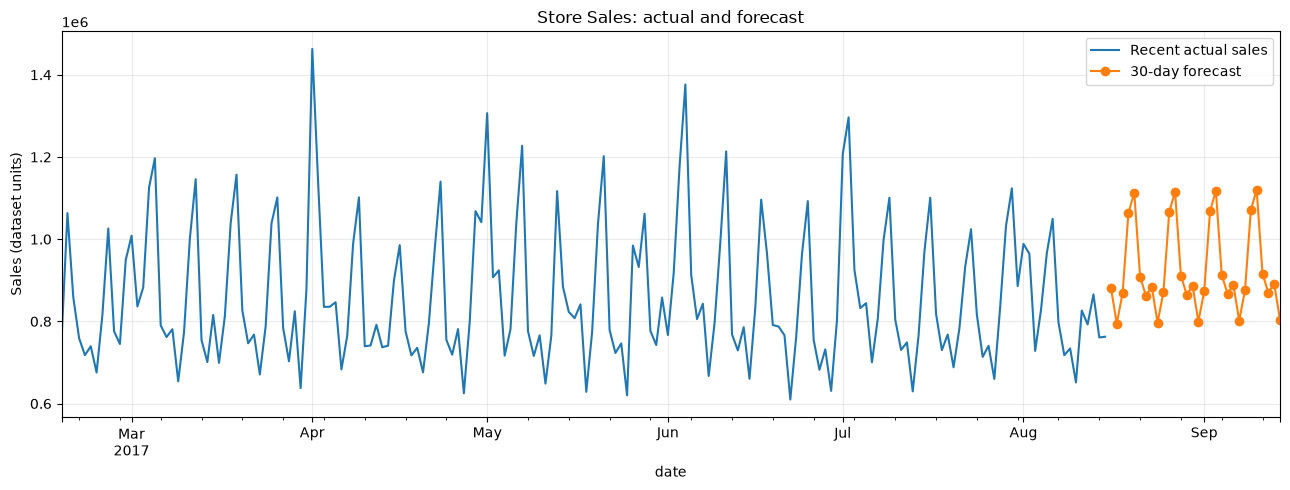

In [12]:
forecast_result = predict_with_artifact(forecast_artifact, periods=30)
observations = pd.DataFrame(forecast_result['observations'])
predictions = pd.DataFrame(forecast_result['forecast'])
observations['date'] = pd.to_datetime(observations['date'], utc=True)
predictions['date'] = pd.to_datetime(predictions['date'], utc=True)

display(predictions.head())

fig, ax = plt.subplots(figsize=(13, 5))
observations.tail(180).set_index('date')['value'].plot(ax=ax, label='Recent actual sales')
predictions.set_index('date')['value'].plot(ax=ax, marker='o', label='30-day forecast')
ax.set_title('Store Sales: actual and forecast')
ax.set_ylabel('Sales (dataset units)')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Step 6: Build daily features for the anomaly model

Daily transaction counts from `transactions.csv` are joined with daily sales. `sales_per_transaction` is an additional numeric feature. If transaction counts are zero or missing, the project's anomaly trainer imputes them with the median.

In [13]:
transactions = pd.read_csv(
    DATA_DIR / 'transactions.csv',
    usecols=['date', 'transactions'],
    parse_dates=['date'],
    dtype={'transactions': 'float32'},
    low_memory=False,
).dropna(subset=['date', 'transactions'])

daily_transactions = (
    transactions.groupby('date')['transactions']
    .sum()
    .sort_index()
    .rename('transactions')
)

daily_features = daily_sales.join(daily_transactions, how='left')
daily_features['sales_per_transaction'] = daily_features['sales'].div(
    daily_features['transactions'].where(daily_features['transactions'] > 0)
)
ANOMALY_FEATURES = ['sales', 'transactions', 'sales_per_transaction']

print(f'Daily feature rows: {len(daily_features):,}')
print('Missing feature values before trainer imputation:')
display(daily_features[ANOMALY_FEATURES].isna().sum().to_frame('missing_rows'))
display(daily_features.head())

Daily feature rows: 1,684
Missing feature values before trainer imputation:


,missing_rows
sales,0
transactions,2
sales_per_transaction,2


,sales,transactions,sales_per_transaction
date,,,
2013-01-01,2511.619141,770.0,3.261843
2013-01-02,496092.406250,93215.0,5.322023
2013-01-03,361461.250000,78504.0,4.604367
2013-01-04,354459.687500,78494.0,4.515755
2013-01-05,477350.125000,93573.0,5.101366


## Step 7: Train the project's anomaly model and inspect flagged rows

This is an unsupervised Isolation Forest. Because there are no labeled anomalies, flagged rows should not be treated as confirmed errors or business incidents. They are candidates for analyst review.

In [14]:
anomaly_rows = daily_features.reset_index().to_dict('records')
anomaly_dataset_id = uuid4()
anomaly_data_version = 'store-sales-transactions-v1'

anomaly_artifact, anomaly_metrics, anomaly_trained_at = train_anomaly_model(
    dataset_id=anomaly_dataset_id,
    feature_columns=ANOMALY_FEATURES,
    data_version=anomaly_data_version,
    rows=anomaly_rows,
)

save_model_artifact('anomaly', anomaly_artifact, ANOMALY_FEATURES)
print(f'Trained at: {anomaly_trained_at}')
display(pd.DataFrame([anomaly_metrics]))

anomaly_result = detect_with_artifact(anomaly_artifact, anomaly_rows)
top_anomalies = pd.DataFrame(anomaly_result['anomalies'])
if not top_anomalies.empty:
    top_anomalies['date'] = top_anomalies['rowIndex'].map(daily_features.reset_index()['date'])
    display(top_anomalies[['date', 'score', 'values']].head(10))
else:
    print('No anomalies were flagged.')

Trained at: 2026-11-25T15:03:22.290551+00:00


,training_rows,flagged_training_rows,feature_count,contamination
0,1684,85,3,0.05


,date,score,values
0,2016-12-24,0.169868,"{'sales': 1246837.875, 'transactions': 167542...."
1,2016-12-23,0.168085,"{'sales': 1282145.5, 'transactions': 156932.0,..."
2,2015-12-24,0.166236,"{'sales': 1083680.25, 'transactions': 171169.0..."
3,2017-04-01,0.154761,"{'sales': 1463084.0, 'transactions': 113083.0,..."
4,2014-12-24,0.154678,"{'sales': 965982.875, 'transactions': 156546.0..."
5,2013-12-24,0.151773,"{'sales': 620663.25, 'transactions': 155846.0,..."
6,2015-12-23,0.151288,"{'sales': 1196146.0, 'transactions': 153338.0,..."
7,2016-01-04,0.139465,"{'sales': 955956.9375, 'transactions': 17829.0..."
8,2017-01-02,0.139389,"{'sales': 1402306.375, 'transactions': 107718...."
9,2013-01-01,0.138696,"{'sales': 2511.619140625, 'transactions': 770...."


## Results and limitations

- Forecasting and anomaly training use the project's `app/ml/` functions, so the AI service's Python environment must have the required dependencies installed.
- The forecast target is daily Store Sales `sales` units. Without unit-price data, it should not be described as revenue.
- The anomaly model learns patterns from the training data; review flagged observations before acting on them.
- The notebook saves artifacts to the configured backend. Local mode writes under `ai-service/models/artifacts`; S3 mode requires a private bucket and deployment credentials.
- Notebook runs use generated dataset IDs and versions, so their models are separate from app-uploaded datasets. Train app-specific models through the authenticated UI/API flow.